In [159]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

In [ ]:
MAX_ITERACOES = 40
INERCIA = 0.5
COGNITIVO = 0.8
SOCIAL = 0.1
QTD_PARTICULAS = 40

In [161]:
particulas = pd.DataFrame(columns=['x', 'y', 'fitness', 'velocidade_x', 'velocidade_y', 'pbest_x', 'pbest_y', 'pbest'])

In [162]:
def calcula_fitness(x, y): # QUER MINIMIZAR A FUNÇÃO FITNESS, ENTÃO QUANTO MENOR O VALOR, MELHOR
    return x**2 + y**2

In [163]:
def calcula_velocidade(inercia, cognitivo, social,velocidade, posicao, pbest, gbest):
    r1 = np.random.random()
    r2 = np.random.random()

    return (inercia * velocidade
        + r1 * cognitivo * (pbest - posicao)
        + r2 * social * (gbest - posicao)
    )

In [ ]:
def inicializa_particulas(quantidade):
    for i in range(quantidade):
        x = np.random.uniform(-10, 10)
        y = np.random.uniform(-10, 10)
        fitness = calcula_fitness(x, y)
        velocidade_x = np.random.uniform(-1, 1)
        velocidade_y = np.random.uniform(-1, 1)
        pbest = fitness
        particulas.loc[i] = [x, y, fitness, velocidade_x, velocidade_y,x,y, pbest]

In [165]:
historico = []

# Salva a posição inicial
historico.append((0, particulas[['x', 'y']].copy()))

In [166]:
inicializa_particulas(QTD_PARTICULAS)

melhor_index = particulas['fitness'].idxmin()

gbest_x = particulas.at[melhor_index, 'x']
gbest_y = particulas.at[melhor_index, 'y']
gbest = particulas.at[melhor_index, 'fitness']

for iteracao in range(MAX_ITERACOES):
    for index, row in particulas.iterrows():

        particulas.at[index, 'velocidade_x'] = calcula_velocidade(INERCIA, COGNITIVO, SOCIAL, row['velocidade_x'], row['x'],row['pbest_x'], gbest_x)
        particulas.at[index, 'velocidade_y'] = calcula_velocidade(INERCIA, COGNITIVO, SOCIAL, row['velocidade_y'], row['y'],row['pbest_y'], gbest_y)
        particulas.at[index, 'x'] += particulas.at[index, 'velocidade_x']
        particulas.at[index, 'y'] += particulas.at[index, 'velocidade_y']
        fitness = calcula_fitness(particulas.at[index, 'x'], particulas.at[index, 'y'])
        particulas.at[index,'fitness'] = fitness

        if fitness < row['pbest']:
            particulas.at[index, "pbest"] = fitness
            particulas.at[index, "pbest_x"] = particulas.at[index, "x"]
            particulas.at[index, "pbest_y"] = particulas.at[index, "y"]

        melhor_index = particulas['fitness'].idxmin()

        if particulas.at[melhor_index, 'fitness'] < gbest:
            gbest_x = particulas.at[melhor_index, 'x']
            gbest_y = particulas.at[melhor_index, 'y']
            gbest = particulas.at[melhor_index, 'fitness']

    if (iteracao + 1) % 10 == 0:
        historico.append((iteracao + 1, particulas[['x', 'y']].copy()))

In [167]:
print("Melhor solução:", gbest_x, gbest_y)
print("Melhor fitness:", gbest)

Melhor solução: -0.006113550756121797 0.0035698085489071054
Melhor fitness: 5.011903592352765e-05


In [168]:
particulas.head()

,x,y,fitness,velocidade_x,velocidade_y,pbest_x,pbest_y,pbest
0,0.060183,0.039039,0.005146,-0.009435,-0.003265,0.060183,0.039039,0.005146
1,0.062381,-0.036033,0.005190,-0.006077,0.002697,0.062381,-0.036033,0.005190
2,-0.166409,-0.021930,0.028173,0.028131,0.003401,-0.166409,-0.021930,0.028173
3,0.007633,-0.005241,0.000086,-0.000781,0.000985,0.007633,-0.005241,0.000086
4,0.018198,0.045134,0.002368,-0.002791,-0.004749,0.018198,0.045134,0.002368


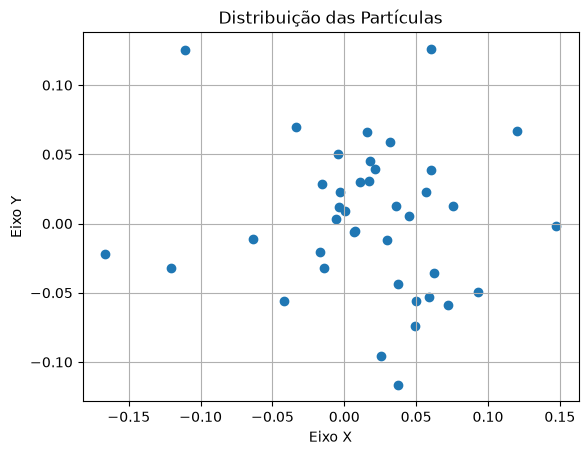

In [169]:
plt.scatter(particulas['x'], particulas['y'])

plt.xlabel('Eixo X')
plt.ylabel('Eixo Y')
plt.title('Distribuição das Partículas')
plt.grid(True)

plt.show()

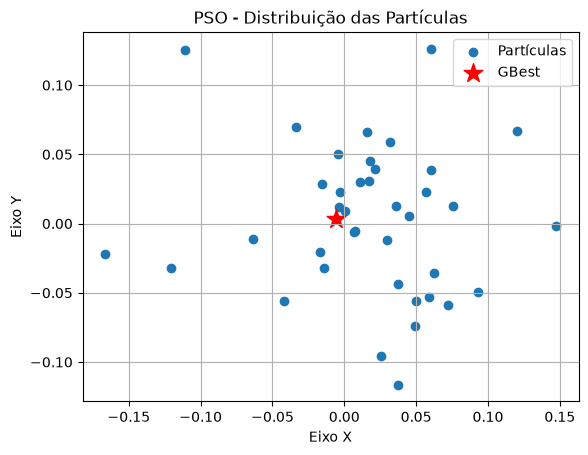

In [170]:
plt.scatter(particulas['x'], particulas['y'], label='Partículas')

plt.scatter(gbest_x, gbest_y, color='red', marker='*',
            s=200, label='GBest')

plt.xlabel('Eixo X')
plt.ylabel('Eixo Y')
plt.title('PSO - Distribuição das Partículas')
plt.legend()
plt.grid(True)

plt.show()

In [171]:
for iteracao, posicoes in historico:
    print(f"\nIteração: {iteracao}")
    print(posicoes.describe())


Iteração: 0
          x    y
count     0    0
unique    0    0
top     NaN  NaN
freq    NaN  NaN

Iteração: 10
               x          y
count  40.000000  40.000000
mean    0.460612  -0.493934
std     2.038777   1.914380
min    -4.113322  -3.993852
25%    -1.014009  -1.902642
50%     0.700043  -0.288806
75%     2.113341   0.987716
max     3.249478   3.107887

Iteração: 20
               x          y
count  40.000000  40.000000
mean    0.252233  -0.064029
std     0.623957   0.614375
min    -1.373942  -1.148941
25%    -0.148581  -0.515773
50%     0.341437  -0.101651
75%     0.732543   0.366835
max     1.490745   1.680021

Iteração: 30
               x          y
count  40.000000  40.000000
mean    0.058411  -0.018672
std     0.202283   0.188467
min    -0.542079  -0.406191
25%    -0.033372  -0.161122
50%     0.076186  -0.004686
75%     0.183147   0.087873
max     0.422858   0.563833

Iteração: 40
               x          y
count  40.000000  40.000000
mean    0.016124   0.002359
std   

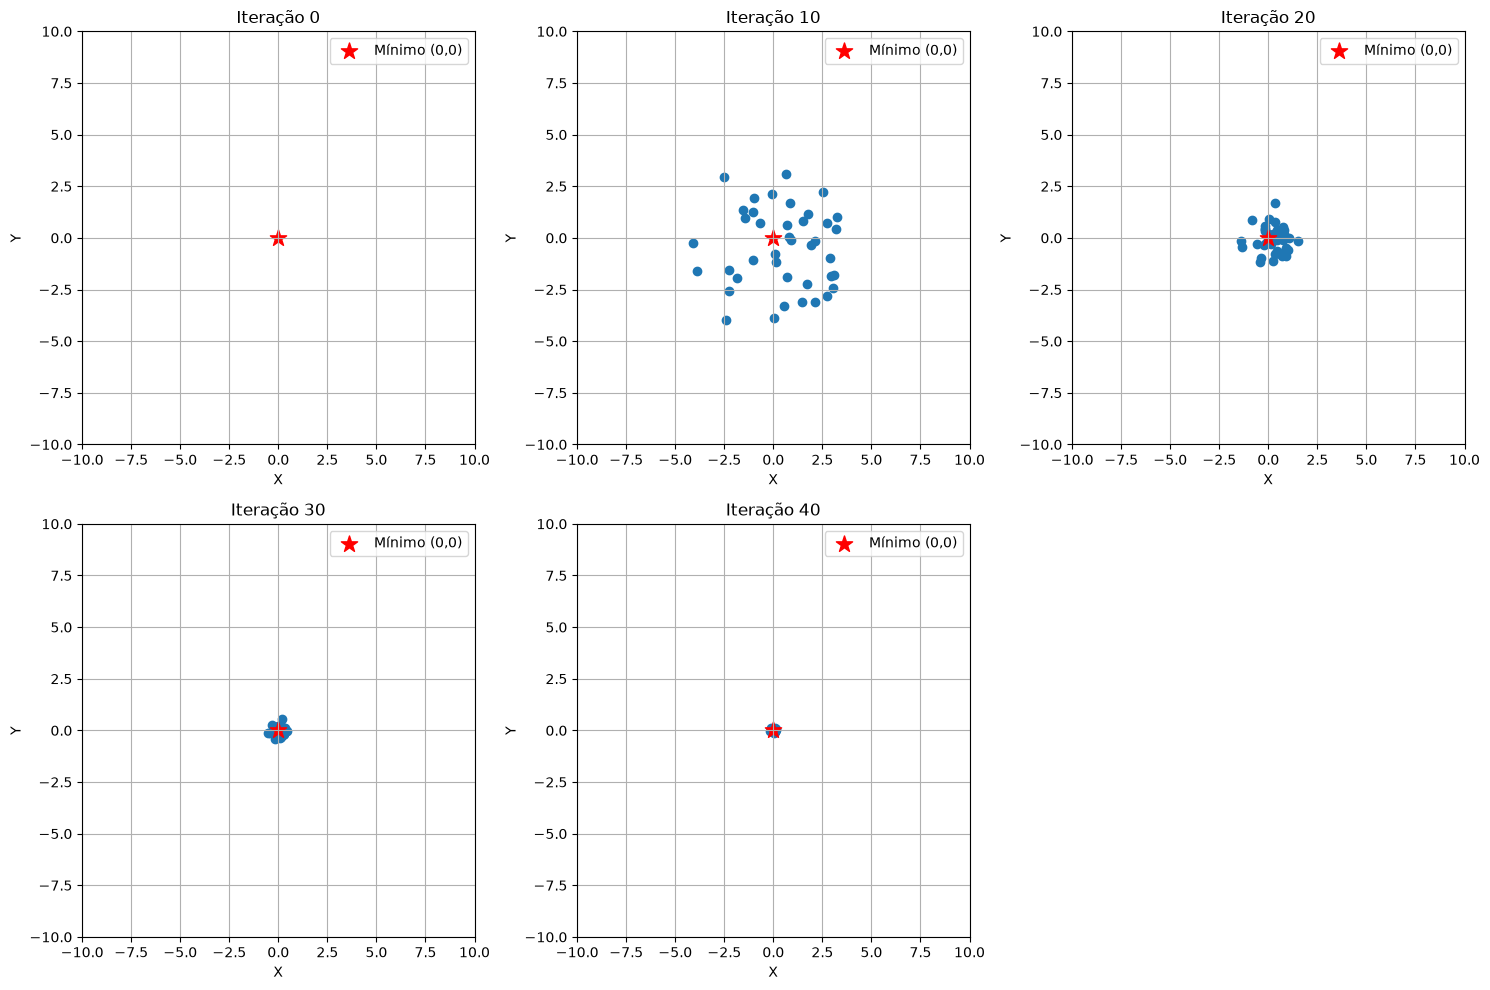

In [172]:

colunas = 3
linhas = math.ceil(len(historico) / colunas)

fig, axes = plt.subplots(
    linhas, colunas,
    figsize=(15, 5 * linhas),
    squeeze=False
)

axes = axes.flatten()

for i, (numero_iteracao, posicoes) in enumerate(historico):

    axes[i].scatter(posicoes['x'], posicoes['y'])

    axes[i].scatter(
        0, 0,
        color='red',
        marker='*',
        s=150,
        label='Mínimo (0,0)'
    )

    axes[i].set_title(f'Iteração {numero_iteracao}')
    axes[i].set_xlim(-10, 10)
    axes[i].set_ylim(-10, 10)
    axes[i].set_xlabel('X')
    axes[i].set_ylabel('Y')
    axes[i].grid()
    axes[i].legend()

for i in range(len(historico), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()